# Plot OBS data

## import things

In [1]:
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns



import matplotlib.pyplot as plt
%matplotlib inline

/work/bb1376/user/leonie/conda/envs/MA_numpy23/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# Disable a few warnings:
import warnings

warnings.filterwarnings("ignore", category=UserWarning, append=True)
warnings.filterwarnings("ignore", category=RuntimeWarning, append=True)
warnings.filterwarnings("ignore", category=FutureWarning, append=True)


In [3]:
# load tools
import sys 
sys.path.append("../tools")
import handle_OBS_data
import plots_mapping

## Set date

In [4]:
# set date
date = "2023-06-06-1800"

## Load data

In [5]:

# combi function   
tb = handle_OBS_data.load_calc_clean_mean_tb(date, buffer = 32, min_images= 5)
precip = handle_OBS_data.load_calc_clean_mean_imerg(date, buffer = 30, min_images= 5)
iwp = handle_OBS_data.load_calc_clean_mean_ccic(date, buffer = 32, min_images= 5)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Tb data loaded for 2023-06-06-1800, if applicable both images returned, cropped, 'Tb' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

...

IMERG data loaded for 2023-06-06-1600, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

IMERG data loaded for 2023-06-06-1530, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim
CCIC data loaded for 2023-06-06-1800, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1700, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1600, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1500, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim


## resample to coarse res 

In [6]:
# resample (data, precip)
tb_res = handle_OBS_data.resample_grids(tb,precip)  
iwp_res = handle_OBS_data.resample_grids(iwp,precip)  


In [7]:
tb

<xarray.DataArray 'Tb' (latitude: 1758, longitude: 9896)> Size: 70MB
dask.array<mean_agg-aggregate, shape=(1758, 9896), dtype=float32, chunksize=(879, 2474), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float32 7kB -31.96 -31.93 -31.89 ... 31.89 31.93 31.96
  * longitude  (longitude) float32 40kB -180.0 -179.9 -179.9 ... 179.9 180.0
    time       datetime64[us] 8B 2023-06-06T18:00:00
Attributes:
    units:          K
    standard_name:  brightness_temperature
    long_name:      Nasa-Tb
    short_name:     Tb

## plots

In [8]:
# simple plot (Mollweide)

# import plots_mapping
# import seaborn as sns
# sns.set_context("notebook")

#ax, pcm = plots_mapping.plot_tb_map_simple(tb,cmap=plots_mapping.tb_colormap())
#ax, pcm = plots_mapping.plot_precip_map_simple(precip, cmap= plots_mapping.precip_colormap())


In [9]:
# import os
# output_directory = "../output/plots"
# if not os.path.exists(os.path.join(output_directory)):
#     os.makedirs(os.path.join(output_directory,), exist_ok=True)
# fig.savefig(os.path.join(output_directory,f"joined_OBS_{date}.png"))

# compare snapshot with mean

In [10]:
# load data
tb_snap = handle_OBS_data.load_clean_crop_tb(date,32)
precip_snap = handle_OBS_data.load_clean_crop_imerg(date,32)
iwp_snap = handle_OBS_data.load_clean_crop_ccic(date,32)

# resample (data, precip)
tb_snap_res = handle_OBS_data.resample_grids(tb_snap,precip_snap)  
iwp_snap_res = handle_OBS_data.resample_grids(iwp_snap,precip_snap)  

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Tb data loaded for 2023-06-06-1800, cropped, 'Tb' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

IMERG data loaded for 2023-06-06-1800, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim
CCIC data loaded for 2023-06-06-1800, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim


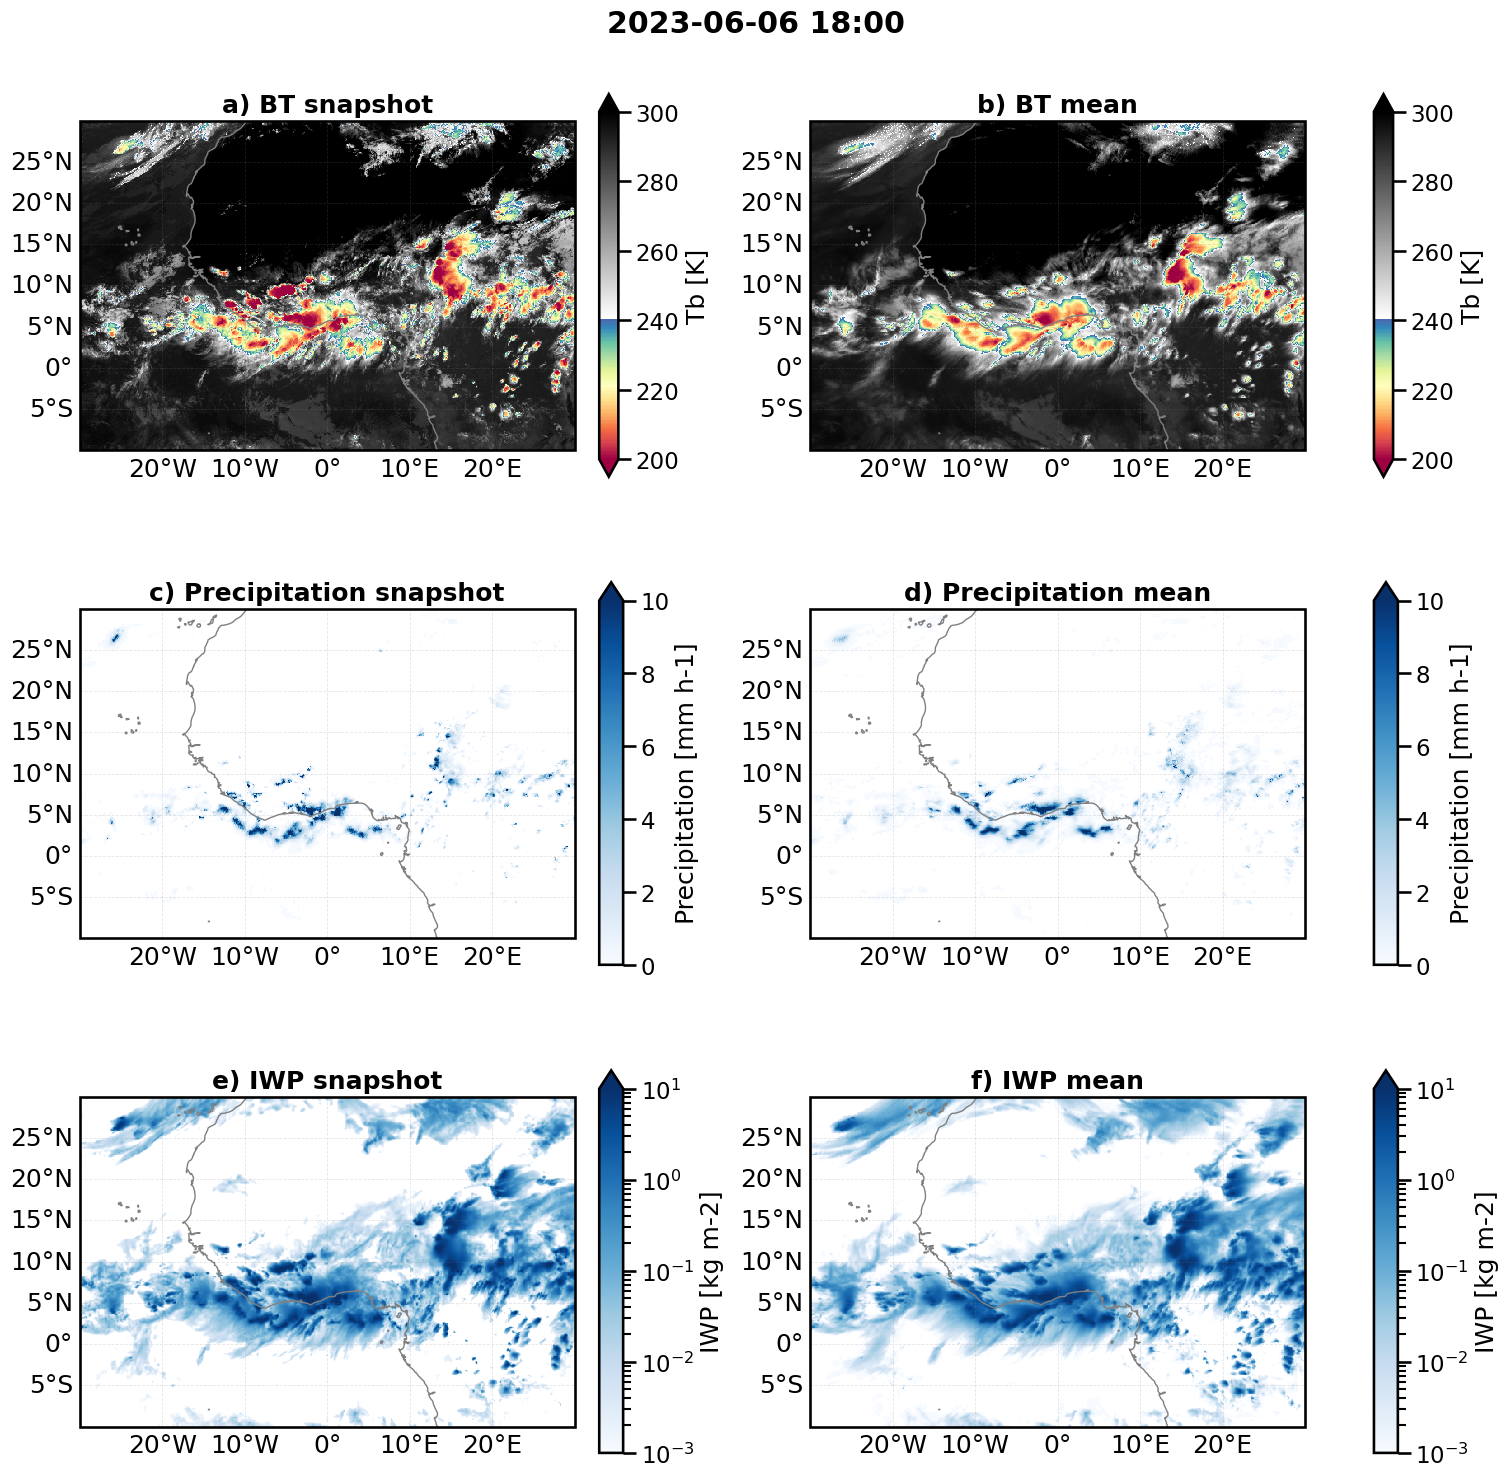

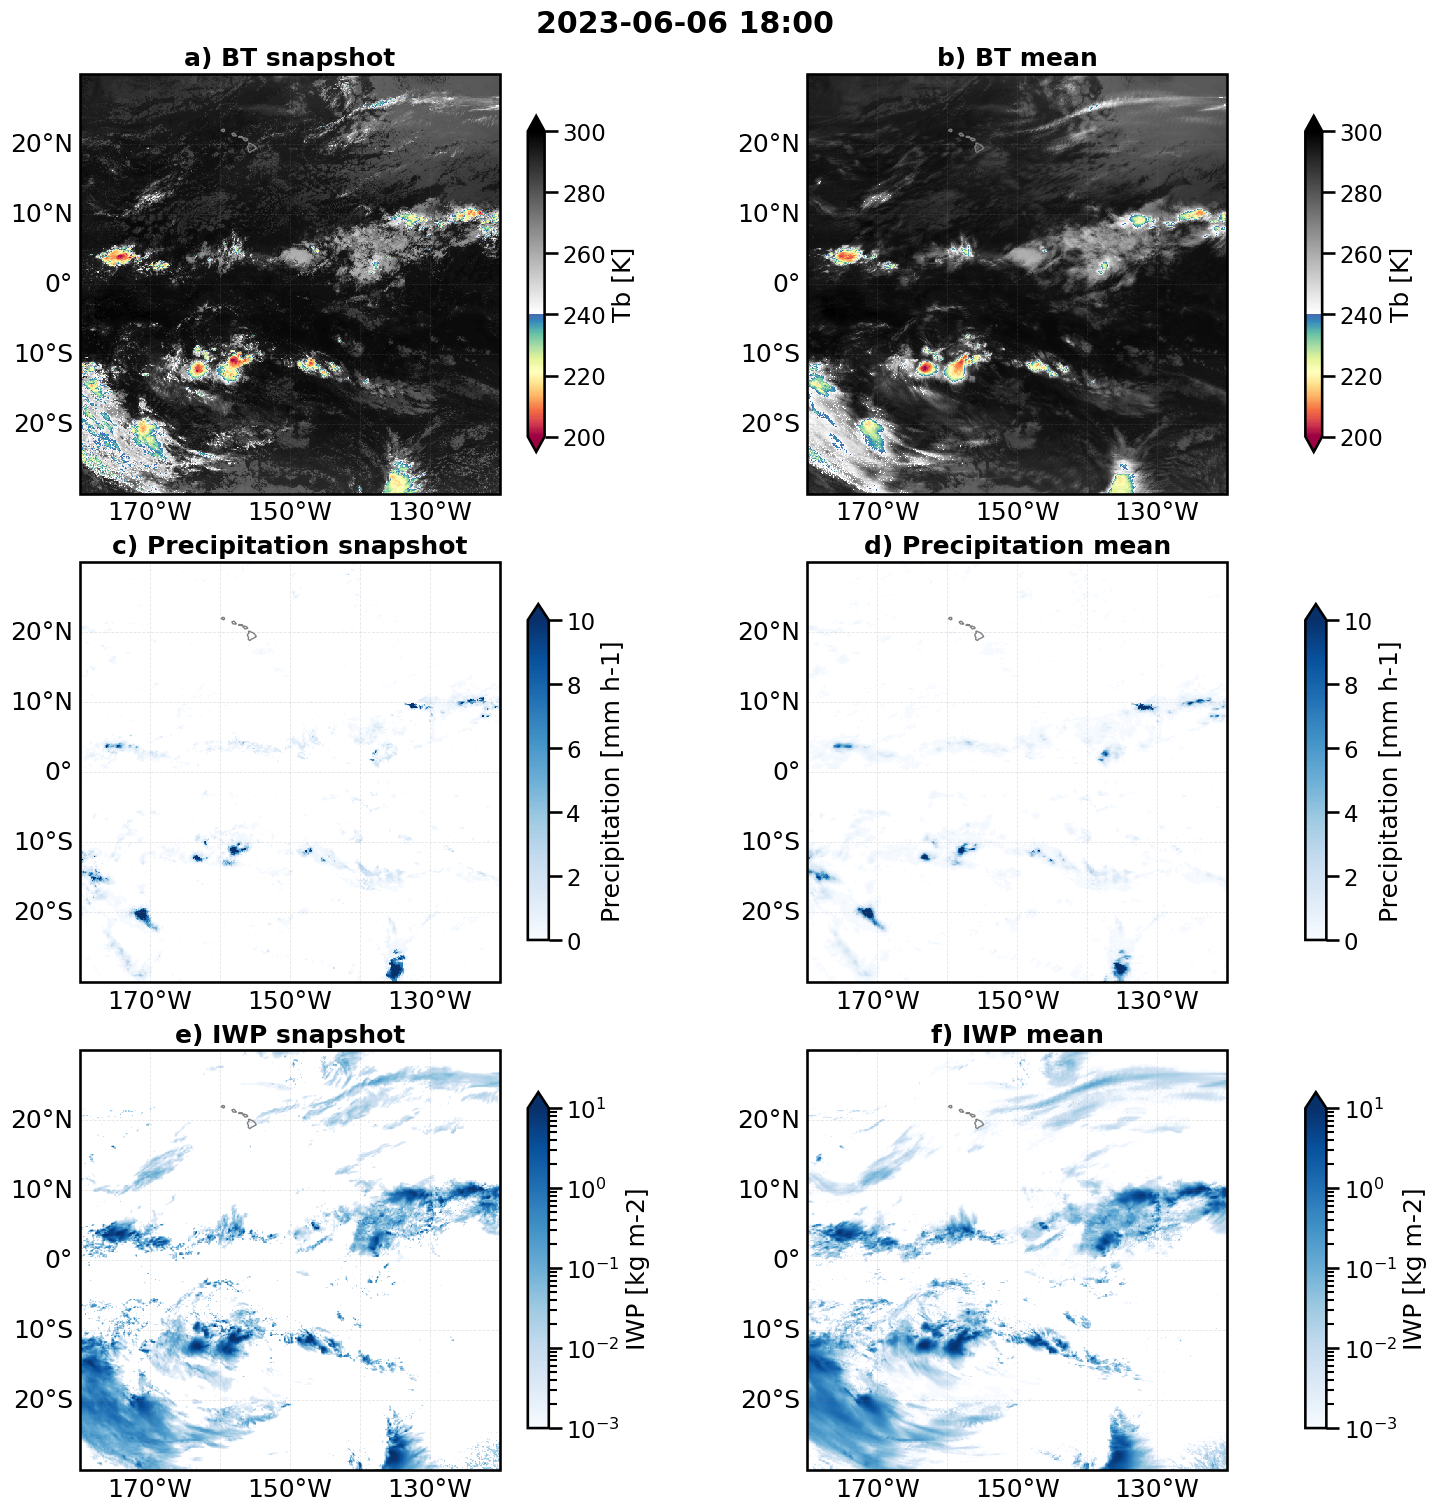


KeyboardInterrupt



Error in callback <function flush_figures at 0x1554d243bd80> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



In [11]:
sns.set_context("talk")
#plt.style.use('tex')
from defs_application import georegions 
# def georegion 
#georegion = "africa_0"

date_title = plots_mapping.title_time_format(tb_res) #str(tb_res.time.values)#

for georegion in georegions.keys():
    if georegion == "global":
        continue

    # plot
    fig, axes = plt.subplots(
        3, 2,
        figsize=(15, 15),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout = True
    )
    # anvil snap
    fig, axes[0, 0], _ = plots_mapping.domain_plot_tb(tb_snap_res, domain=georegions[georegion], title="a) BT snapshot", fig=fig, ax=axes[0, 0])
 
    # tb mean
    fig, axes[0, 1], _ = plots_mapping.domain_plot_tb(tb_res, domain=georegions[georegion], title="b) BT mean", fig=fig, ax=axes[0, 1])

    # precip snap
    fig, axes[1, 0], _ = plots_mapping.domain_plot_precip(precip_snap,vmin = 0, vmax = 10, domain=georegions[georegion], title="c) Precipitation snapshot", fig=fig, ax=axes[1, 0])

    # precip mean
    fig, axes[1, 1], _ = plots_mapping.domain_plot_precip(precip,vmin = 0, vmax = 10, domain=georegions[georegion], title="d) Precipitation mean", fig=fig, ax=axes[1, 1])

    # # iwp snap
    fig, axes[2, 0], _ = plots_mapping.domain_plot_iwp(iwp_snap_res,vmin = 1e-3, vmax = 1e1, domain=georegions[georegion], title="e) IWP snapshot", fig=fig, ax=axes[2, 0])
    
    # # iwp mean
    fig, axes[2, 1], _ = plots_mapping.domain_plot_iwp(iwp_res,vmin = 1e-3, vmax = 1e1, domain=georegions[georegion], title="f) IWP mean", fig=fig, ax=axes[2, 1])
 
    fig.suptitle(f"{date_title}", fontweight="bold")
    
    # solve unequal subplot soizes due to colorbar
    # reserve colorbar space for segmentation plot
    dummy = plt.cm.ScalarMappable(cmap="Greys")
    cbar = fig.colorbar(dummy, ax=axes[0, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[2, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    
    #plt.tight_layout()
    
    plt.savefig(f"../output/plots/joined_OBS_ {georegion}_snap_and_mean_{date}.pdf",dpi=150, bbox_inches='tight')
    
    plt.show()
    